# 2.d) Validate Soil Suitability — comparaison au raster officiel GAEZ v5

Compare notre calcul (Maize, rainfed — la seule combinaison culture/régime pour laquelle GAEZ v5
publie une référence exploitable) au raster réel `SQX.SQ0` (bucket public FAO/IIASA), pour les
niveaux Low/Intermediate/High, à résolution native (30 arc-sec, pixel à pixel — la mesure la plus
rigoureuse, voir `GAEZ_v5_Pipeline_Documentation.docx` §4.2).

**Ce que GAEZ v5 publie réellement, et les limites que ça impose** :
- Seulement HIM (High) et LIM (Low) — pas d'Intermediate publié. On compare donc High vs HIM et Low
  vs LIM directement, et Intermediate vs (HIM+LIM)/2 en approximation.
- Aucune distinction rainfed/irrigué documentée dans les métadonnées GAEZ — hypothèse de travail :
  SQX ≈ rainfed (le wiki présente systématiquement le rainfed comme le cas de base).
- Paramétré pour le maïs uniquement (`"using maize as the reference crop"`) — donc seule la
  comparaison Maize est possible.
- Publié en 10 classes de 10% (Byte, pas continu) — plafonne la corrélation atteignable même pour
  une réplique parfaite.

**Architecture validée** : calcul par composant du sol (chaque unité de sol séparément, résultats
pondérés par part de surface ensuite) — voir `2.c)`. Confirmé empiriquement bien plus fidèle que
mélanger les entrées avant de calculer (Spearman 0.71 → 0.84 sur Intermediate).


## 1. Configuration

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import pearsonr, spearmanr
import urllib.request

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
HWSD_TIF = cu.data_file(CFG, "hwsd_raster")  # data path: see 00_config_and_inventory.ipynb
SMU_DIR = cu.out_dir(CFG, "2_soil_suitability")              # SMU tables of 2.c
OUT_DIR = cu.out_dir(CFG, "2_soil_suitability", "validation")   # FAO rasters downloaded + figures
FIG_DIR = OUT_DIR / "validation_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FAO_SQ0_HIM_URL = "https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET/SQX/GAEZ-V5.SQX.SQ0.HIM.tif"
FAO_SQ0_LIM_URL = "https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET/SQX/GAEZ-V5.SQX.SQ0.LIM.tif"
fao_him_path = OUT_DIR / "_validation_fao_sqx_sq0_maize_him.tif"
fao_lim_path = OUT_DIR / "_validation_fao_sqx_sq0_maize_lim.tif"
if not fao_him_path.exists():
    urllib.request.urlretrieve(FAO_SQ0_HIM_URL, fao_him_path)
if not fao_lim_path.exists():
    urllib.request.urlretrieve(FAO_SQ0_LIM_URL, fao_lim_path)

SMU_PKL = SMU_DIR / "_maize_rf_by_smu.pkl"
if not SMU_PKL.exists():
    raise FileNotFoundError("Run 2.c)_Build_SoilSuitability_HWSD.ipynb first - it produces this file.")
maize_rf = pd.read_pickle(SMU_PKL)
max_smu = int(maize_rf['SMU_ID'].max())
print('loaded native SMU table:', maize_rf.shape)


loaded native SMU table: (28857, 6)


## 1bis. Agrégation 0.25° sur place (pour les cartes uniquement)

Ce notebook ne dépend pas de `2.e)` : il fait sa propre agrégation légère, seulement pour les
visuels de comparaison (les statistiques, elles, restent calculées à résolution native ci-dessous).

In [2]:
def aggregate_ours_025(smu_ids, values, agg=30):
    lut = np.full(max_smu + 1, np.nan, dtype=np.float32)
    lut[smu_ids.astype(int)] = values.astype(np.float32)
    with rasterio.open(HWSD_TIF) as src:
        W, H = src.width, src.height
        nodata = src.nodata
        out_w, out_h = W // agg, H // agg
        acc = np.full((out_h, out_w), np.nan, dtype=np.float32)
        for by in range(out_h):
            block = src.read(1, window=Window(0, by * agg, W, agg))
            valid = (block != nodata) & (block <= max_smu)
            vals = np.full(block.shape, np.nan, dtype=np.float32)
            vals[valid] = lut[block[valid]]
            vals_r = vals.reshape(agg, out_w, agg)
            with np.errstate(invalid='ignore'):
                acc[by, :] = np.nanmean(vals_r, axis=(0, 2))
    return acc


coords025 = {'lat': np.linspace(90 - 0.125, -90 + 0.125, 720), 'lon': np.linspace(-180 + 0.125, 180 - 0.125, 1440)}
ours_int = xr.DataArray(aggregate_ours_025(maize_rf['SMU_ID'].values, maize_rf['SSR_int'].values), dims=('lat', 'lon'), coords=coords025)
ours_low = xr.DataArray(aggregate_ours_025(maize_rf['SMU_ID'].values, maize_rf['SSR_low'].values), dims=('lat', 'lon'), coords=coords025)
ours_high = xr.DataArray(aggregate_ours_025(maize_rf['SMU_ID'].values, maize_rf['SSR_high'].values), dims=('lat', 'lon'), coords=coords025)
print('ours aggregated to 0.25deg for plotting:', ours_int.shape)


C:\Users\elisa\AppData\Local\Temp\ipykernel_89728\2937855211.py:16: RuntimeWarning: Mean of empty slice
  acc[by, :] = np.nanmean(vals_r, axis=(0, 2))


C:\Users\elisa\AppData\Local\Temp\ipykernel_89728\2937855211.py:16: RuntimeWarning: Mean of empty slice
  acc[by, :] = np.nanmean(vals_r, axis=(0, 2))


ours aggregated to 0.25deg for plotting: (720, 1440)


## 2. Statistiques de validation — résolution native (pixel à pixel, 30 arc-sec)

Pas d'agrégation avant comparaison : agréger *avant* de comparer gonfle artificiellement la
corrélation en lissant le désaccord indépendant pixel à pixel (effet statistique connu, pas un
artefact — voir doc Word). Échantillonnage aléatoire pour rester raisonnable en temps de calcul.

In [3]:
def sample_native(smu_ids, values, fao_him_path, fao_lim_path, max_smu, n_per_row=500, row_step=50, seed=42):
    lut = np.full(max_smu + 1, np.nan, dtype=np.float32)
    lut[smu_ids.astype(int)] = values.astype(np.float32)
    rng = np.random.default_rng(seed)
    ours_s, him_s, lim_s = [], [], []
    with rasterio.open(HWSD_TIF) as src_h, rasterio.open(fao_him_path) as src_him, rasterio.open(fao_lim_path) as src_lim:
        H, W = src_h.height, src_h.width
        nodata = src_h.nodata
        for row in range(0, H, row_step):
            hblock = src_h.read(1, window=Window(0, row, W, 1))[0]
            himblock = src_him.read(1, window=Window(0, row, W, 1))[0].astype(np.float32)
            limblock = src_lim.read(1, window=Window(0, row, W, 1))[0].astype(np.float32)
            valid_h = (hblock != nodata) & (hblock <= max_smu)
            ov = np.full(W, np.nan, dtype=np.float32)
            ov[valid_h] = lut[hblock[valid_h]]
            him_mid = (himblock - 0.5) * 10.0
            him_mid[(himblock < 1) | (himblock > 10)] = np.nan
            lim_mid = (limblock - 0.5) * 10.0
            lim_mid[(limblock < 1) | (limblock > 10)] = np.nan
            both = np.isfinite(ov) & np.isfinite(him_mid) & np.isfinite(lim_mid)
            if both.sum() == 0:
                continue
            idx = np.where(both)[0]
            if len(idx) > n_per_row:
                idx = rng.choice(idx, n_per_row, replace=False)
            ours_s.append(ov[idx]); him_s.append(him_mid[idx]); lim_s.append(lim_mid[idx])
    return np.concatenate(ours_s), np.concatenate(him_s), np.concatenate(lim_s)


o_low, him_l, lim_l = sample_native(maize_rf['SMU_ID'].values, maize_rf['SSR_low'].values, fao_him_path, fao_lim_path, max_smu)
o_int, him_i, lim_i = sample_native(maize_rf['SMU_ID'].values, maize_rf['SSR_int'].values, fao_him_path, fao_lim_path, max_smu)
o_high, him_h, lim_h = sample_native(maize_rf['SMU_ID'].values, maize_rf['SSR_high'].values, fao_him_path, fao_lim_path, max_smu)

def stats(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    pr, _ = pearsonr(x[ok], y[ok])
    sr, _ = spearmanr(x[ok], y[ok])
    return dict(n=int(ok.sum()), pearson=round(pr, 3), spearman=round(sr, 3),
                mean_ours=round(x[ok].mean(), 1), mean_fao=round(y[ok].mean(), 1))

rows = [
    dict(comparison='SSR_high vs FAO HIM', **stats(o_high, him_h)),
    dict(comparison='SSR_low vs FAO LIM', **stats(o_low, lim_l)),
    dict(comparison='SSR_int vs FAO (HIM+LIM)/2', **stats(o_int, (him_i + lim_i) / 2)),
]
stats_df = pd.DataFrame(rows)
stats_df


,comparison,n,pearson,spearman,mean_ours,mean_fao
0,SSR_high vs FAO HIM,150886,0.824,0.842,58.799999,59.700001
1,SSR_low vs FAO LIM,150886,0.853,0.846,43.599998,45.000000
2,SSR_int vs FAO (HIM+LIM)/2,150886,0.813,0.816,45.599998,52.299999


## 3. Tableau de validation (image)

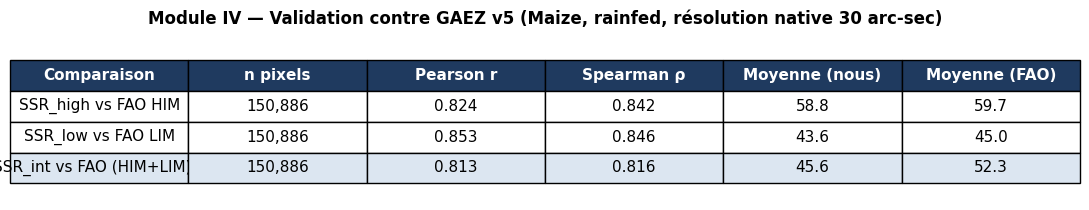

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.axis('off')
col_labels = ['Comparaison', 'n pixels', 'Pearson r', 'Spearman ρ', 'Moyenne (nous)', 'Moyenne (FAO)']
cell_text = [[r['comparison'], f"{r['n']:,}", r['pearson'], r['spearman'], r['mean_ours'], r['mean_fao']]
             for r in rows]
table = ax.table(cellText=cell_text, colLabels=col_labels, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.0)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor('#1F3A5F')
        cell.set_text_props(color='white', fontweight='bold')
    elif r == 3:  # SSR_int row - our production layer, highlight
        cell.set_facecolor('#DCE6F1')
plt.title('Module IV — Validation contre GAEZ v5 (Maize, rainfed, résolution native 30 arc-sec)',
          fontsize=12, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig(FIG_DIR / 'validation_stats_table.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. Cartes de comparaison (notre carte | GAEZ v5 | différence)

Agrégées à 0.25° pour la visualisation (la résolution native serait illisible sur une figure).

C:\Users\elisa\AppData\Local\Temp\ipykernel_89728\3650052246.py:12: RuntimeWarning: Mean of empty slice
  acc[by, :] = np.nanmean(vals_r, axis=(0, 2))


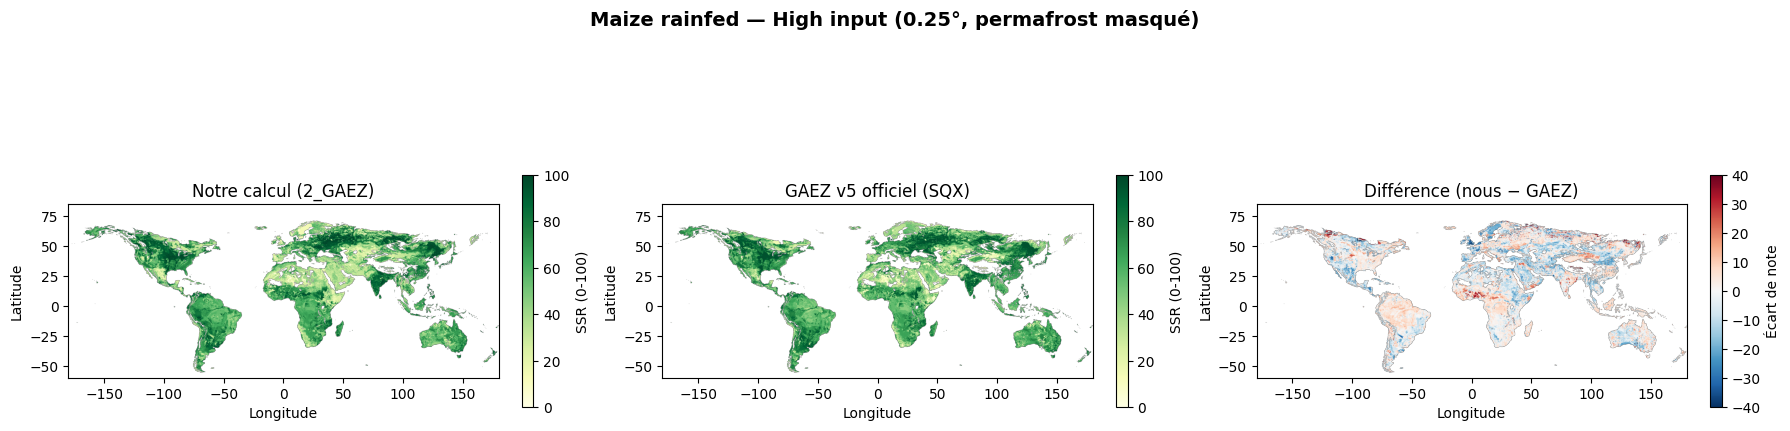

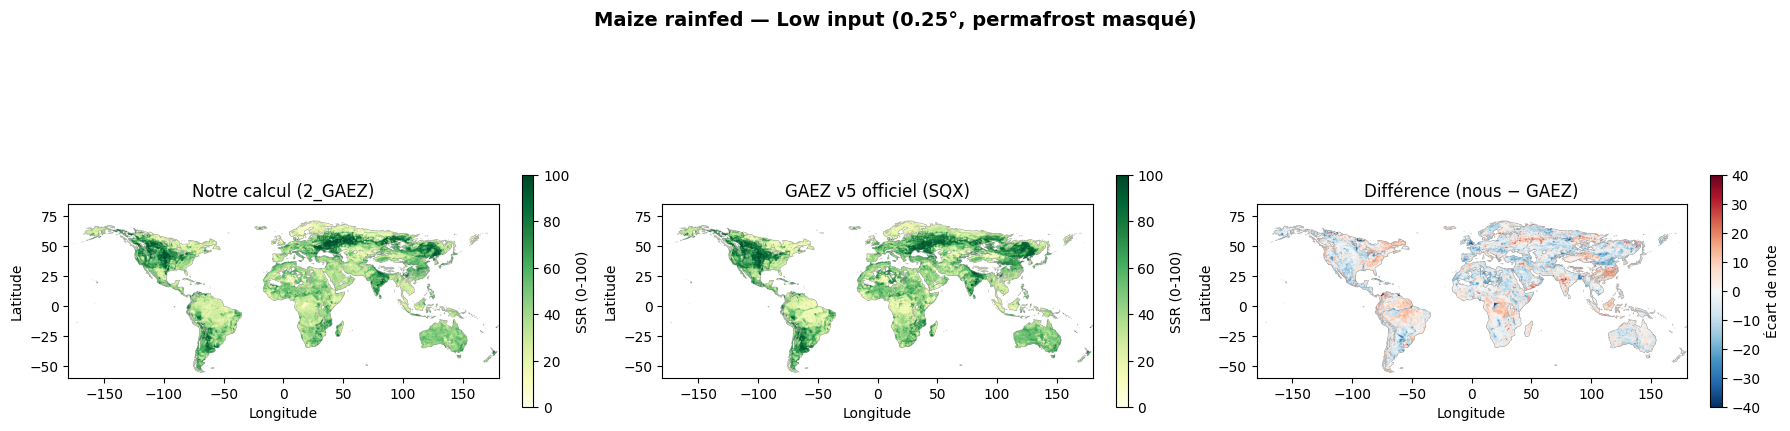

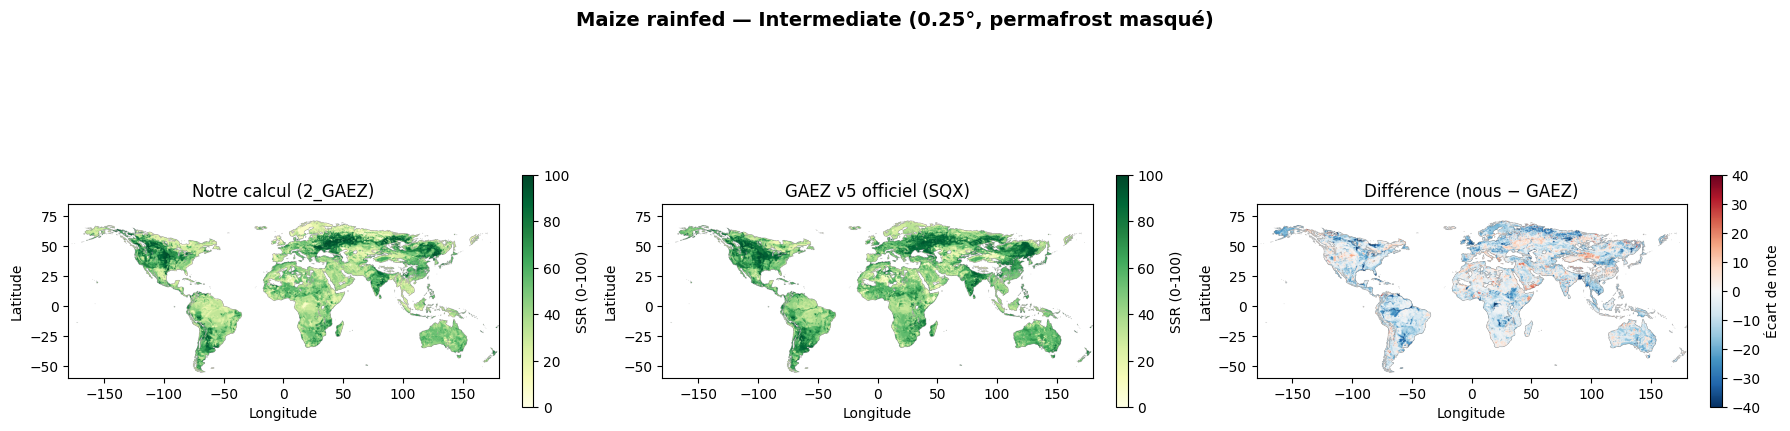

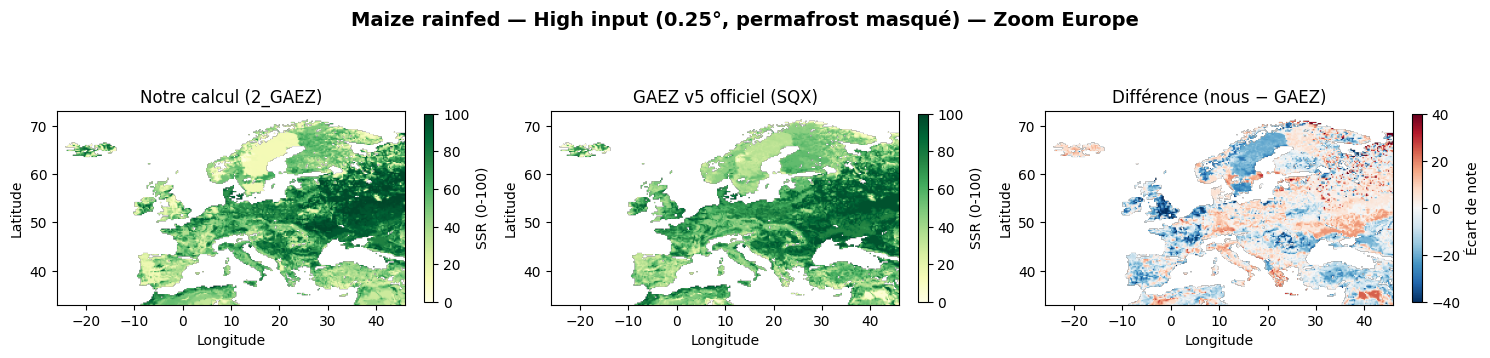

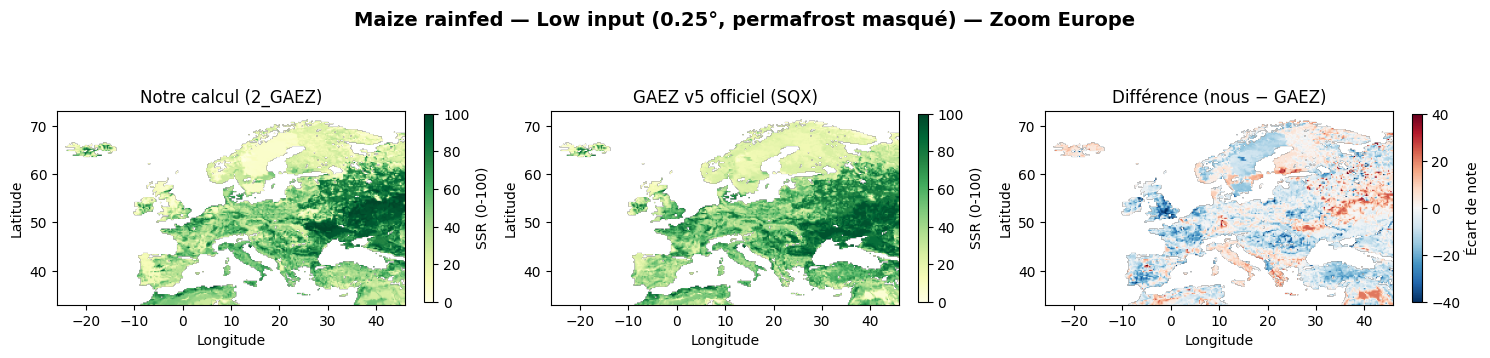

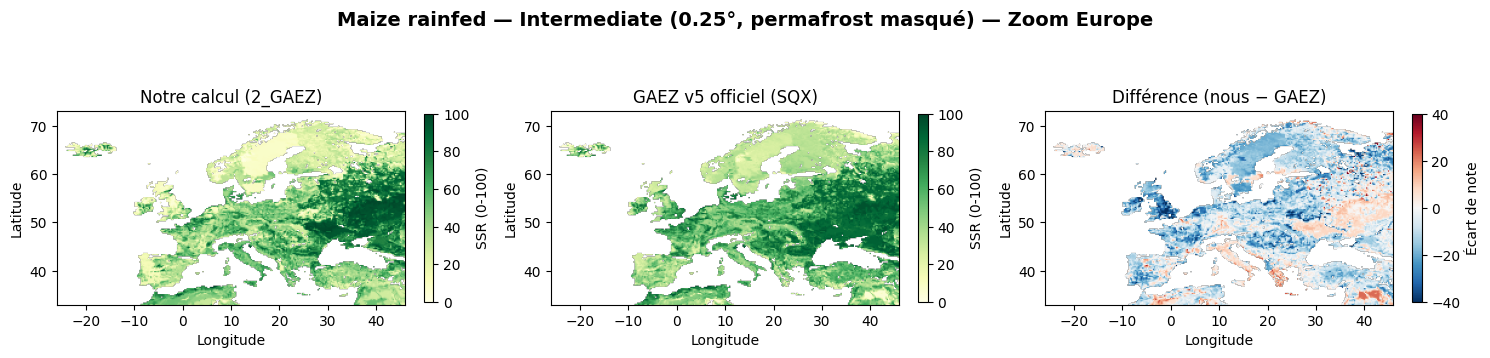

In [5]:
def aggregate_fao_025(tif_path, agg=30):
    with rasterio.open(tif_path) as src:
        out_h, out_w = src.height // agg, src.width // agg
        acc = np.full((out_h, out_w), np.nan, dtype=np.float32)
        pf = np.zeros((out_h, out_w), dtype=np.float32)
        for by in range(out_h):
            block = src.read(1, window=Window(0, by * agg, src.width, agg)).astype(np.float32)
            mid = (block - 0.5) * 10.0
            mid[(block < 1) | (block > 10)] = np.nan
            vals_r = mid.reshape(agg, out_w, agg)
            with np.errstate(invalid='ignore'):
                acc[by, :] = np.nanmean(vals_r, axis=(0, 2))
            # BUGFIX (trouve en relisant la carte globale avec l'utilisatrice, 2026-10-13) : `is_pf`
            # ne comptait QUE la classe 11 (pergelisol au sens strict). Verifie sur le raster brut
            # (distribution des classes, bande 55-80N) : il existe une classe 12 bien plus etendue
            # (34.3% de cette bande, contre 1.97% pour la classe 11 -- couvre la majeure partie du
            # Groenland, du nord Canada et de la Siberie extreme), deja correctement exclue du calcul
            # de score ci-dessus (`mid`, qui rejette tout x hors [1,10]) mais PAS comptee ici -- donc
            # le masque de la carte (base sur `pf`) ratait ces zones : la carte GAEZ y est NaN (via
            # `mid`) mais notre propre carte n'etait pas masquee au meme endroit (pas la meme
            # condition), d'ou l'incoherence visible (GAEZ blanc, nous colore, au meme pixel).
            # Corrige en alignant exactement sur la condition de `mid` : toute classe hors [1,10],
            # quelle que soit sa signification precise (pergelisol, calotte glaciaire, non evalue...).
            is_excluded = ((block < 1) | (block > 10)).astype(np.float32)
            pf[by, :] = is_excluded.reshape(agg, out_w, agg).mean(axis=(0, 2))
    return acc, pf


fao_him_025, pf_025 = aggregate_fao_025(fao_him_path)
fao_lim_025, _ = aggregate_fao_025(fao_lim_path)
fao_int_025 = (fao_him_025 + fao_lim_025) / 2.0

fao_da = lambda arr: xr.DataArray(arr, dims=('lat', 'lon'), coords=ours_int.coords)
fao_him_da = fao_da(fao_him_025)
fao_lim_da = fao_da(fao_lim_025)
fao_int_da = fao_da(fao_int_025)
pf_da = fao_da(pf_025)

# `pf_da` est maintenant la fraction de pixels natifs "hors classe suitability 1-10" dans le bloc
# 0.25deg (pergelisol classe 11, classe 12 -- calottes/zones non evaluees, et toute autre valeur
# hors plage), pas seulement le pergelisol au sens strict -- voir BUGFIX ci-dessus. Seuil >= 50% du
# bloc, comme vise par le commentaire d'origine ("mask permafrost >=50% of block").
mask_pf = pf_da >= 0.5

# Emprise Europe pour les cartes zoomees (meme convention que le pipeline 1_SVM : lat 35-71, lon -25-44,
# avec une petite marge ici puisqu'on part d'une grille 0.25deg globale, pas d'un decoupage prealable)
EUROPE_EXTENT = (-26, 46, 33, 73)  # (lon_min, lon_max, lat_min, lat_max)


def three_panel(ours_map, fao_map, title, fname, extent=None):
    diff = ours_map - fao_map
    if extent is None:
        figsize, xlim, ylim = (18, 5.5), (-180, 180), (-60, 85)
    else:
        lon_min, lon_max, lat_min, lat_max = extent
        aspect = (lon_max - lon_min) / (lat_max - lat_min)
        # largeur totale fixee, hauteur deduite de l'aspect reel des donnees (pas un facteur arbitraire)
        # pour que chaque panneau (aspect='equal') remplisse sa boite sans bande blanche residuelle :
        # ~78% de la largeur d'un panneau sert a la carte (le reste = colorbar + marges), le reste de la
        # hauteur de figure (~1.6 pouce) est reserve aux titres/labels.
        total_w = 15.0
        map_w = (total_w / 3) * 0.78
        map_h = map_w / aspect
        figsize = (total_w, map_h + 1.6)
        xlim, ylim = (lon_min, lon_max), (lat_min, lat_max)
    fig, axes = plt.subplots(1, 3, figsize=figsize, subplot_kw={'aspect': 'equal'})
    vmin, vmax = 0, 100
    im0 = axes[0].imshow(ours_map.where(~mask_pf), origin='upper', extent=[-180, 180, -90, 90],
                          cmap='YlGn', vmin=vmin, vmax=vmax)
    axes[0].set_title('Notre calcul (2_GAEZ)')
    plt.colorbar(im0, ax=axes[0], fraction=0.025, label='SSR (0-100)')
    im1 = axes[1].imshow(fao_map.where(~mask_pf), origin='upper', extent=[-180, 180, -90, 90],
                          cmap='YlGn', vmin=vmin, vmax=vmax)
    axes[1].set_title('GAEZ v5 officiel (SQX)')
    plt.colorbar(im1, ax=axes[1], fraction=0.025, label='SSR (0-100)')
    dmax = 40
    im2 = axes[2].imshow(diff.where(~mask_pf), origin='upper', extent=[-180, 180, -90, 90],
                          cmap='RdBu_r', vmin=-dmax, vmax=dmax)
    axes[2].set_title('Différence (nous − GAEZ)')
    plt.colorbar(im2, ax=axes[2], fraction=0.025, label='Écart de note')
    for ax in axes:
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=180, bbox_inches='tight')
    plt.show()


three_panel(ours_high, fao_him_da, 'Maize rainfed — High input (0.25°, permafrost masqué)',
            'compare_maize_rf_high_vs_HIM.png')
three_panel(ours_low, fao_lim_da, 'Maize rainfed — Low input (0.25°, permafrost masqué)',
            'compare_maize_rf_low_vs_LIM.png')
three_panel(ours_int, fao_int_da, 'Maize rainfed — Intermediate (0.25°, permafrost masqué)',
            'compare_maize_rf_intermediate_vs_approxHIMLIM.png')

# Memes cartes, zoomees sur l'Europe
three_panel(ours_high, fao_him_da, 'Maize rainfed — High input (0.25°, permafrost masqué) — Zoom Europe',
            'compare_maize_rf_high_vs_HIM_europe.png', extent=EUROPE_EXTENT)
three_panel(ours_low, fao_lim_da, 'Maize rainfed — Low input (0.25°, permafrost masqué) — Zoom Europe',
            'compare_maize_rf_low_vs_LIM_europe.png', extent=EUROPE_EXTENT)
three_panel(ours_int, fao_int_da, 'Maize rainfed — Intermediate (0.25°, permafrost masqué) — Zoom Europe',
            'compare_maize_rf_intermediate_vs_approxHIMLIM_europe.png', extent=EUROPE_EXTENT)


## 5. Cartes binaires (seuil SSR ≥ 40 = « suitable ») — où notre carte se trompe

Les cartes continues ci-dessus montrent l'écart de *note*, mais pas directement si une décision
pratique (« ce pixel est-il cultivable ou non ? ») change de côté. On binarise donc les deux cartes
au même seuil, puis on classe chaque pixel en 4 catégories : accord suitable, accord unsuitable,
**sur-estimation** (nous disons suitable, GAEZ dit non) et **sous-estimation** (nous disons
unsuitable, GAEZ dit oui) — ce qui isole visuellement et statistiquement les zones de vrai désaccord.

**Seuil retenu : SSR ≥ 40.** Choix justifié par le découpage officiel GAEZ en 6 classes de
suitability (`NS/VmS/mS/MS/S/VS`, bornes à 0/20/40/60/80/100 — voir la formule `SI` documentée dans
`GAEZ_v5_Pipeline_Documentation.docx`) : 40 est la borne entre « marginalement suitable » (mS,
20-40) et « modérément suitable » (MS, 40-60), c.-à-d. la limite usuelle entre terre marginale et
terre considérée comme réellement cultivable. Le seuil est un paramètre (`THRESH_BIN`), facilement
modifiable.

Les statistiques (exactitude, taux de sur/sous-estimation) sont calculées à **résolution native**
(même échantillon que la section 2 — 152 206 pixels), pas sur les cartes agrégées à 0.25° utilisées
pour l'affichage, pour rester cohérent avec la méthodologie de validation la plus rigoureuse.

In [6]:
THRESH_BIN = 40  # seuil SSR : >= 40 = "suitable" (borne mS/MS dans le decoupage a 6 classes de GAEZ)


def binary_stats(ours, fao, thresh):
    ok = np.isfinite(ours) & np.isfinite(fao)
    ob = ours[ok] >= thresh
    fb = fao[ok] >= thresh
    agree_suit = np.mean(ob & fb)
    agree_unsuit = np.mean(~ob & ~fb)
    over = np.mean(ob & ~fb)    # nous: suitable, GAEZ: unsuitable (sur-estimation)
    under = np.mean(~ob & fb)   # nous: unsuitable, GAEZ: suitable (sous-estimation)
    return dict(n=int(ok.sum()), threshold=thresh, accuracy=round(agree_suit + agree_unsuit, 3),
                agree_suitable=round(agree_suit, 3), agree_unsuitable=round(agree_unsuit, 3),
                over_estimation=round(over, 3), under_estimation=round(under, 3))


binary_rows = [
    dict(comparison='SSR_high vs FAO HIM', **binary_stats(o_high, him_h, THRESH_BIN)),
    dict(comparison='SSR_low vs FAO LIM', **binary_stats(o_low, lim_l, THRESH_BIN)),
    dict(comparison='SSR_int vs FAO (HIM+LIM)/2', **binary_stats(o_int, (him_i + lim_i) / 2, THRESH_BIN)),
]
binary_stats_df = pd.DataFrame(binary_rows)
binary_stats_df


,comparison,n,threshold,accuracy,agree_suitable,agree_unsuitable,over_estimation,under_estimation
0,SSR_high vs FAO HIM,150886,40,0.859,0.732,0.128,0.032,0.108
1,SSR_low vs FAO LIM,150886,40,0.856,0.444,0.412,0.058,0.086
2,SSR_int vs FAO (HIM+LIM)/2,150886,40,0.776,0.528,0.248,0.018,0.206


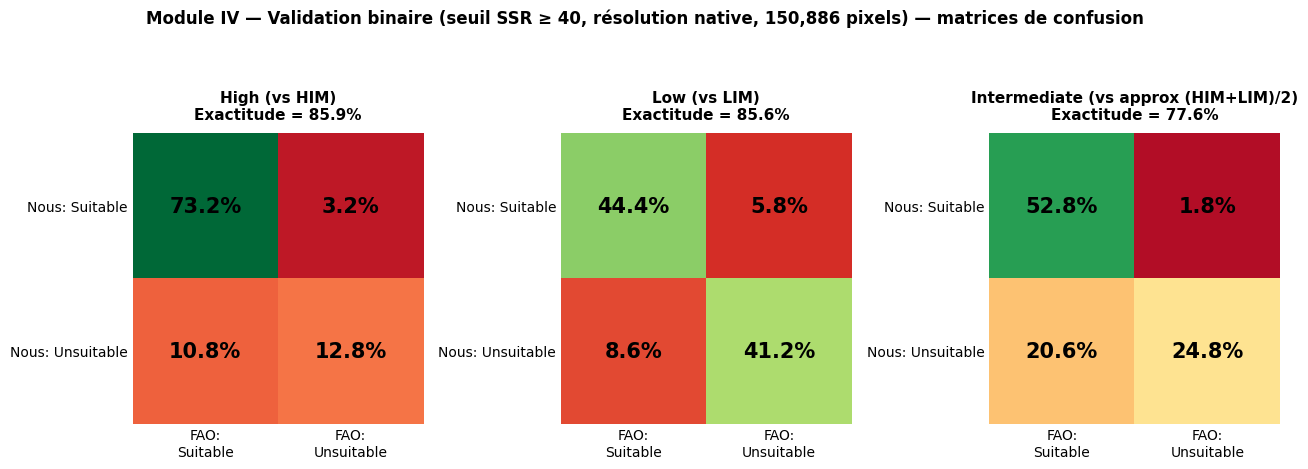

In [7]:
# Matrices de confusion (en %) - plus lisible qu'un tableau de colonnes a decoder : chaque case montre
# directement la fraction de pixels dans cette combinaison (nous x FAO), diagonale = accord (vert),
# hors-diagonale = desaccord (rouge), avec l'exactitude totale rappelee sous chaque matrice.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
levels_cfg = [
    ('High (vs HIM)', binary_rows[0]),
    ('Low (vs LIM)', binary_rows[1]),
    ('Intermediate (vs approx (HIM+LIM)/2)', binary_rows[2]),
]
for ax, (label, r) in zip(axes, levels_cfg):
    mat = np.array([[r['agree_suitable'], r['over_estimation']],
                     [r['under_estimation'], r['agree_unsuitable']]]) * 100
    im = ax.imshow(mat, cmap='RdYlGn', vmin=0, vmax=60)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{mat[i, j]:.1f}%', ha='center', va='center', fontsize=15, fontweight='bold')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['FAO:\nSuitable', 'FAO:\nUnsuitable'], fontsize=10)
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Nous: Suitable', 'Nous: Unsuitable'], fontsize=10)
    ax.set_title(f'{label}\nExactitude = {r["accuracy"]*100:.1f}%', fontsize=11, fontweight='bold', pad=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

fig.suptitle(f'Module IV — Validation binaire (seuil SSR ≥ {THRESH_BIN}, résolution native, '
             f'{binary_rows[0]["n"]:,} pixels) — matrices de confusion',
             fontsize=12, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / f'validation_confusion_matrix_binary{THRESH_BIN}.png', dpi=200, bbox_inches='tight')
plt.show()


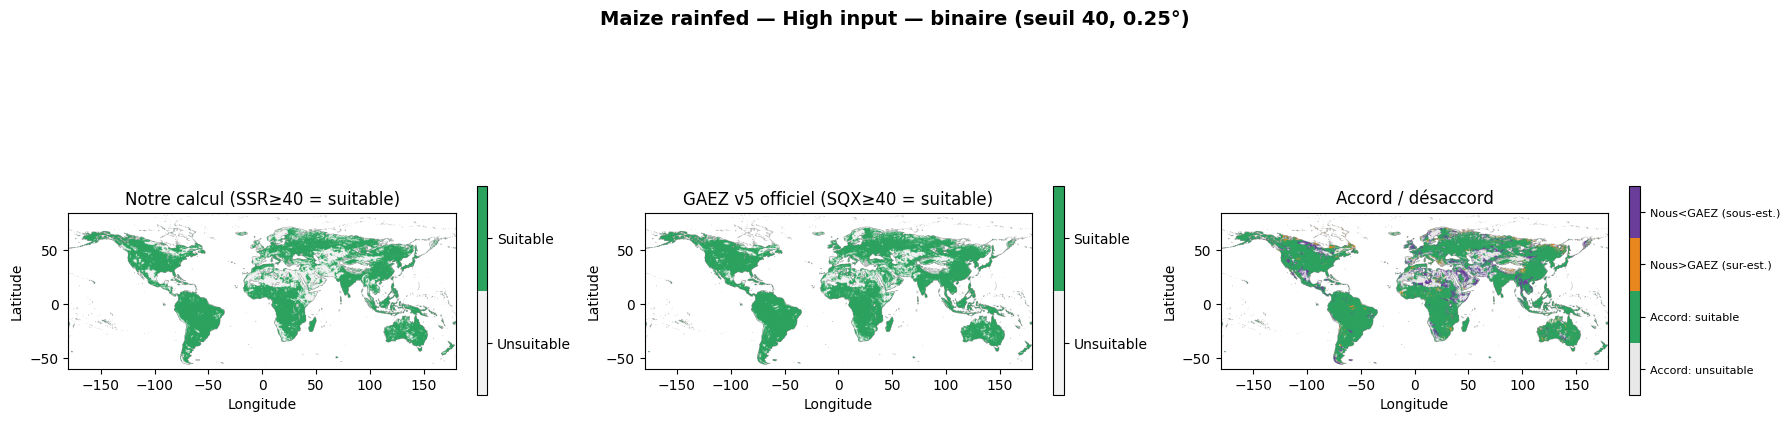

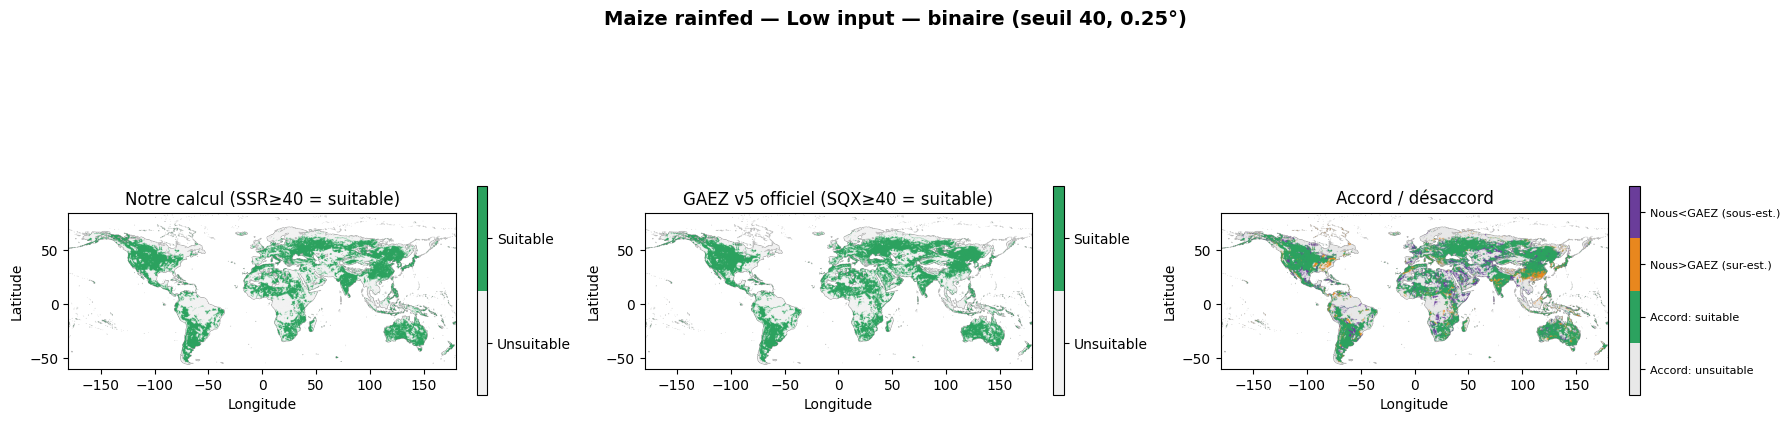

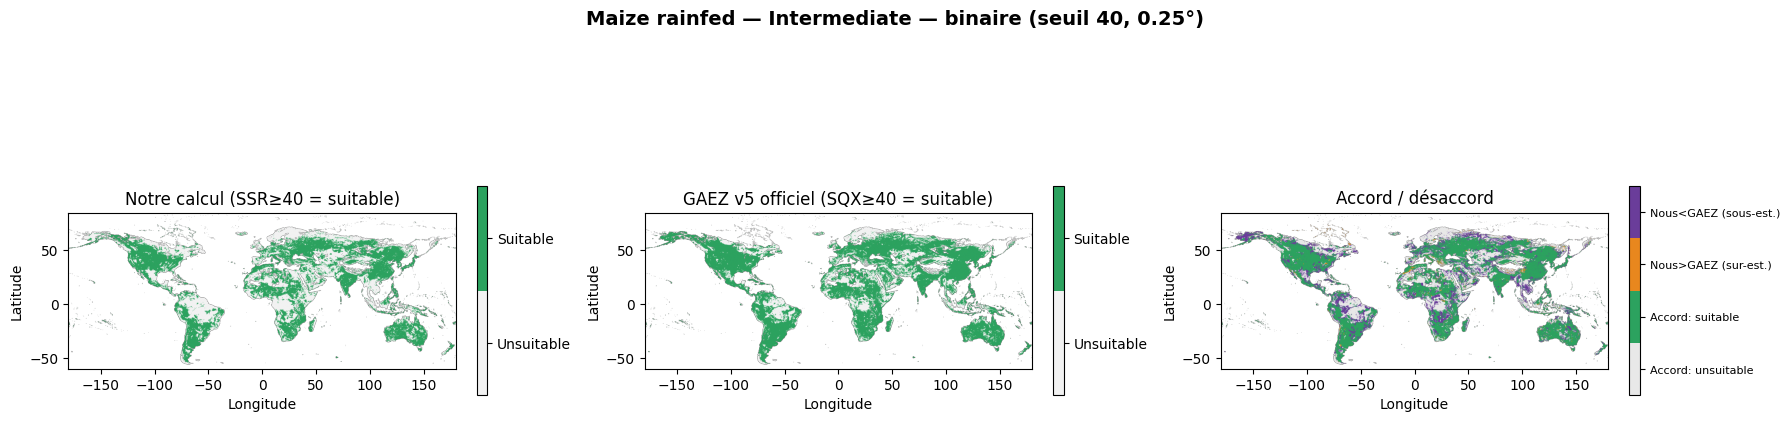

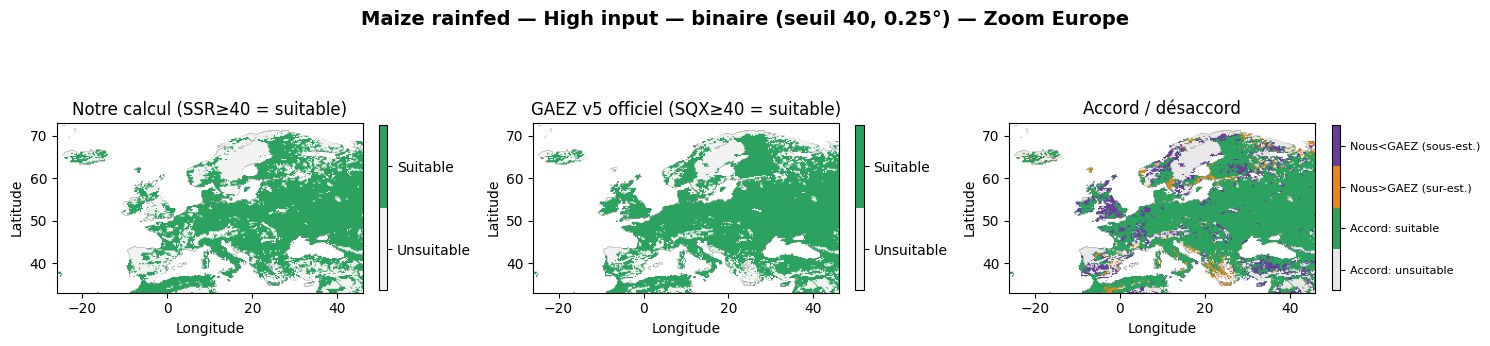

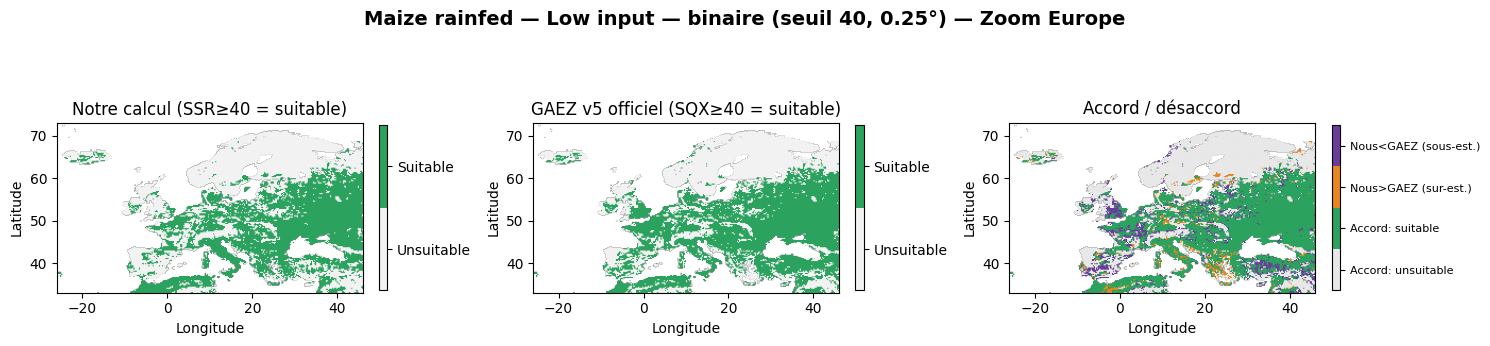

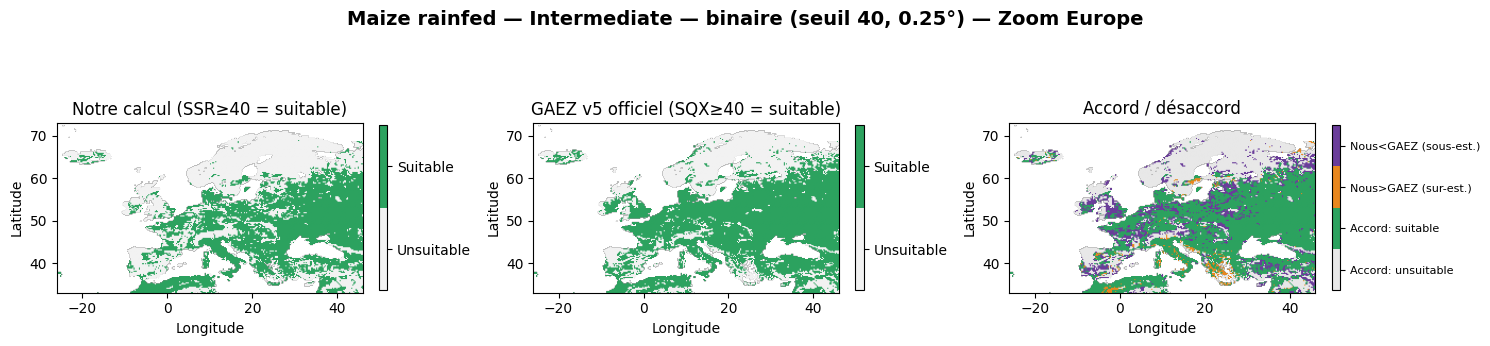

In [8]:
def three_panel_binary(ours_map, fao_map, thresh, title, fname, extent=None):
    valid = np.isfinite(ours_map) & np.isfinite(fao_map) 
    ob = ours_map.values >= thresh
    fb = fao_map.values >= thresh
    v = valid.values

    ours_b = xr.DataArray(np.where(v, ob.astype(float), np.nan), dims=ours_map.dims, coords=ours_map.coords)
    fao_b = xr.DataArray(np.where(v, fb.astype(float), np.nan), dims=ours_map.dims, coords=ours_map.coords)

    # categorie : 0=accord unsuitable, 1=accord suitable, 2=sur-estimation (nous suit./GAEZ unsuit.),
    # 3=sous-estimation (nous unsuit./GAEZ suit.)
    cat_vals = np.full(ours_map.shape, np.nan)
    cat_vals[v & ~ob & ~fb] = 0
    cat_vals[v & ob & fb] = 1
    cat_vals[v & ob & ~fb] = 2
    cat_vals[v & ~ob & fb] = 3
    cat_da = xr.DataArray(cat_vals, dims=ours_map.dims, coords=ours_map.coords)

    if extent is None:
        figsize, xlim, ylim = (18, 5.5), (-180, 180), (-60, 85)
    else:
        lon_min, lon_max, lat_min, lat_max = extent
        aspect = (lon_max - lon_min) / (lat_max - lat_min)
        total_w = 15.0
        map_w = (total_w / 3) * 0.78
        map_h = map_w / aspect
        figsize = (total_w, map_h + 1.6)
        xlim, ylim = (lon_min, lon_max), (lat_min, lat_max)

    fig, axes = plt.subplots(1, 3, figsize=figsize, subplot_kw={'aspect': 'equal'})

    bin_cmap = mcolors.ListedColormap(['#f2f2f2', '#2ca25f'])
    im0 = axes[0].imshow(ours_b, origin='upper', extent=[-180, 180, -90, 90], cmap=bin_cmap, vmin=-0.5, vmax=1.5)
    axes[0].set_title(f'Notre calcul (SSR≥{thresh} = suitable)')
    cb0 = plt.colorbar(im0, ax=axes[0], fraction=0.025, ticks=[0, 1])
    cb0.ax.set_yticklabels(['Unsuitable', 'Suitable'])

    im1 = axes[1].imshow(fao_b, origin='upper', extent=[-180, 180, -90, 90], cmap=bin_cmap, vmin=-0.5, vmax=1.5)
    axes[1].set_title(f'GAEZ v5 officiel (SQX≥{thresh} = suitable)')
    cb1 = plt.colorbar(im1, ax=axes[1], fraction=0.025, ticks=[0, 1])
    cb1.ax.set_yticklabels(['Unsuitable', 'Suitable'])

    cat_cmap = mcolors.ListedColormap(['#e8e8e8', '#2ca25f', '#e8871e', '#6a3d9a'])
    im2 = axes[2].imshow(cat_da, origin='upper', extent=[-180, 180, -90, 90], cmap=cat_cmap, vmin=-0.5, vmax=3.5)
    axes[2].set_title('Accord / désaccord')
    cb2 = plt.colorbar(im2, ax=axes[2], fraction=0.025, ticks=[0, 1, 2, 3])
    cb2.ax.set_yticklabels(['Accord: unsuitable', 'Accord: suitable', 'Nous>GAEZ (sur-est.)', 'Nous<GAEZ (sous-est.)'])
    cb2.ax.tick_params(labelsize=8)

    for ax in axes:
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=180, bbox_inches='tight')
    plt.show()


three_panel_binary(ours_high, fao_him_da, THRESH_BIN,
                    f'Maize rainfed — High input — binaire (seuil {THRESH_BIN}, 0.25°)',
                    f'compare_maize_rf_high_vs_HIM_binary{THRESH_BIN}.png')
three_panel_binary(ours_low, fao_lim_da, THRESH_BIN,
                    f'Maize rainfed — Low input — binaire (seuil {THRESH_BIN}, 0.25°)',
                    f'compare_maize_rf_low_vs_LIM_binary{THRESH_BIN}.png')
three_panel_binary(ours_int, fao_int_da, THRESH_BIN,
                    f'Maize rainfed — Intermediate — binaire (seuil {THRESH_BIN}, 0.25°)',
                    f'compare_maize_rf_intermediate_vs_approxHIMLIM_binary{THRESH_BIN}.png')
three_panel_binary(ours_high, fao_him_da, THRESH_BIN,
                    f'Maize rainfed — High input — binaire (seuil {THRESH_BIN}, 0.25°) — Zoom Europe',
                    f'compare_maize_rf_high_vs_HIM_binary{THRESH_BIN}_europe.png', extent=EUROPE_EXTENT)
three_panel_binary(ours_low, fao_lim_da, THRESH_BIN,
                    f'Maize rainfed — Low input — binaire (seuil {THRESH_BIN}, 0.25°) — Zoom Europe',
                    f'compare_maize_rf_low_vs_LIM_binary{THRESH_BIN}_europe.png', extent=EUROPE_EXTENT)
three_panel_binary(ours_int, fao_int_da, THRESH_BIN,
                    f'Maize rainfed — Intermediate — binaire (seuil {THRESH_BIN}, 0.25°) — Zoom Europe',
                    f'compare_maize_rf_intermediate_vs_approxHIMLIM_binary{THRESH_BIN}_europe.png', extent=EUROPE_EXTENT)


## 6. Validation composant par composant (SQ1 à SQ7)

Jusqu'ici, la validation compare uniquement l'agrégat final (SQ0 côté FAO, notre SSR). Mais le mapset
`SQX` publie aussi `SQ1`...`SQ7` individuellement (les 7 qualités de sol, avant combinaison) — on peut
donc comparer directement chacune de nos qualités de sol intermédiaires à l'équivalent FAO, pour savoir
*laquelle* porte le plus l'écart résiduel documenté (tables de notation v4 plutôt que v5 natives,
pondération par couche approximée — voir `GAEZ_v5_Pipeline_Documentation.docx`).

Maize/rainfed uniquement (seule combinaison validable), Low vs FAO LIM et High vs FAO HIM, à résolution
native (même méthode que la section 2). Nécessite `_maize_rf_sq_components_by_smu.pkl`, produit par la
section 8 de `2.c)`.

In [9]:
SQ_PKL = SMU_DIR / "_maize_rf_sq_components_by_smu.pkl"
if not SQ_PKL.exists():
    raise FileNotFoundError("Run section 8 of 2.c)_Build_SoilSuitability_HWSD.ipynb first.")
sq_df = pd.read_pickle(SQ_PKL)
max_smu_sq = int(sq_df['SMU_ID'].max())
print('loaded SQ1-7 native table:', sq_df.shape)

SQ_NAMES = {1: 'Nutrient availability', 2: 'Nutrient retention capacity', 3: 'Rooting conditions',
            4: 'Oxygen availability (drainage)', 5: 'Salinity/Sodicity tolerance',
            6: 'Lime/Gypsum tolerance', 7: 'Workability'}

FAO_SQ_URL = "https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET/SQX/GAEZ-V5.SQX.SQ{k}.{lvl}.tif"
sq_fao_paths = {}
for k in range(1, 8):
    for lvl in ['HIM', 'LIM']:
        fn = OUT_DIR / f"_validation_fao_sqx_sq{k}_maize_{lvl.lower()}.tif"
        if not fn.exists():
            urllib.request.urlretrieve(FAO_SQ_URL.format(k=k, lvl=lvl), fn)
        sq_fao_paths[(k, lvl)] = fn
print('FAO SQ1-7 HIM/LIM rasters ready (', len(sq_fao_paths), 'files ).')


loaded SQ1-7 native table: (29538, 22)
FAO SQ1-7 HIM/LIM rasters ready ( 14 files ).


In [10]:
def sample_native_generic(values_by_smu, fao_path, max_smu, n_per_row=500, row_step=50, seed=42):
    lut = np.full(max_smu + 1, np.nan, dtype=np.float32)
    lut[sq_df['SMU_ID'].values.astype(int)] = values_by_smu.astype(np.float32)
    rng = np.random.default_rng(seed)
    ours_s, fao_s = [], []
    with rasterio.open(HWSD_TIF) as src_h, rasterio.open(fao_path) as src_f:
        H, W = src_h.height, src_h.width
        nodata = src_h.nodata
        for row in range(0, H, row_step):
            hblock = src_h.read(1, window=Window(0, row, W, 1))[0]
            fblock = src_f.read(1, window=Window(0, row, W, 1))[0].astype(np.float32)
            valid_h = (hblock != nodata) & (hblock <= max_smu)
            ov = np.full(W, np.nan, dtype=np.float32)
            ov[valid_h] = lut[hblock[valid_h]]
            f_mid = (fblock - 0.5) * 10.0
            f_mid[(fblock < 1) | (fblock > 10)] = np.nan
            both = np.isfinite(ov) & np.isfinite(f_mid)
            if both.sum() == 0:
                continue
            idx = np.where(both)[0]
            if len(idx) > n_per_row:
                idx = rng.choice(idx, n_per_row, replace=False)
            ours_s.append(ov[idx]); fao_s.append(f_mid[idx])
    return np.concatenate(ours_s), np.concatenate(fao_s)


def sample_native_pair(values_by_smu, fao_path_him, fao_path_lim, max_smu, n_per_row=500, row_step=50, seed=42):
    # comme sample_native_generic, mais lit HIM et LIM en meme temps pour construire l'approx (HIM+LIM)/2
    lut = np.full(max_smu + 1, np.nan, dtype=np.float32)
    lut[sq_df['SMU_ID'].values.astype(int)] = values_by_smu.astype(np.float32)
    rng = np.random.default_rng(seed)
    ours_s, approx_s = [], []
    with rasterio.open(HWSD_TIF) as src_h, rasterio.open(fao_path_him) as src_him, rasterio.open(fao_path_lim) as src_lim:
        H, W = src_h.height, src_h.width
        nodata = src_h.nodata
        for row in range(0, H, row_step):
            hblock = src_h.read(1, window=Window(0, row, W, 1))[0]
            himblock = src_him.read(1, window=Window(0, row, W, 1))[0].astype(np.float32)
            limblock = src_lim.read(1, window=Window(0, row, W, 1))[0].astype(np.float32)
            valid_h = (hblock != nodata) & (hblock <= max_smu)
            ov = np.full(W, np.nan, dtype=np.float32)
            ov[valid_h] = lut[hblock[valid_h]]
            him_mid = (himblock - 0.5) * 10.0
            him_mid[(himblock < 1) | (himblock > 10)] = np.nan
            lim_mid = (limblock - 0.5) * 10.0
            lim_mid[(limblock < 1) | (limblock > 10)] = np.nan
            approx = (him_mid + lim_mid) / 2.0
            both = np.isfinite(ov) & np.isfinite(approx)
            if both.sum() == 0:
                continue
            idx = np.where(both)[0]
            if len(idx) > n_per_row:
                idx = rng.choice(idx, n_per_row, replace=False)
            ours_s.append(ov[idx]); approx_s.append(approx[idx])
    return np.concatenate(ours_s), np.concatenate(approx_s)


sq_stats_rows = []
for k in range(1, 8):
    row = {'SQ': f'SQ{k}', 'name': SQ_NAMES[k]}
    for lvl, suffix, tag in [('HIM', 'high', 'high'), ('LIM', 'low', 'low')]:
        vals = sq_df[f'SQ{k}_{suffix}'].values
        o, f = sample_native_generic(vals, sq_fao_paths[(k, lvl)], max_smu_sq)
        ok = np.isfinite(o) & np.isfinite(f)
        pr, _ = pearsonr(o[ok], f[ok])
        sr, _ = spearmanr(o[ok], f[ok])
        row[f'n_{tag}'] = int(ok.sum())
        row[f'pearson_{tag}'] = round(pr, 3)
        row[f'spearman_{tag}'] = round(sr, 3)
        row[f'mean_ours_{tag}'] = round(o[ok].mean(), 1)
        row[f'mean_fao_{tag}'] = round(f[ok].mean(), 1)
    # Intermediate vs approximation FAO (HIM+LIM)/2 - meme principe que pour l'agregat SSR_int
    vals_int = sq_df[f'SQ{k}_int'].values
    o, f = sample_native_pair(vals_int, sq_fao_paths[(k, 'HIM')], sq_fao_paths[(k, 'LIM')], max_smu_sq)
    ok = np.isfinite(o) & np.isfinite(f)
    pr, _ = pearsonr(o[ok], f[ok])
    sr, _ = spearmanr(o[ok], f[ok])
    row['n_int'] = int(ok.sum())
    row['pearson_int'] = round(pr, 3)
    row['spearman_int'] = round(sr, 3)
    row['mean_ours_int'] = round(o[ok].mean(), 1)
    row['mean_fao_int'] = round(f[ok].mean(), 1)
    sq_stats_rows.append(row)

sq_stats_df = pd.DataFrame(sq_stats_rows)
sq_stats_df


,SQ,name,n_high,pearson_high,spearman_high,mean_ours_high,mean_fao_high,n_low,pearson_low,spearman_low,mean_ours_low,mean_fao_low,n_int,pearson_int,spearman_int,mean_ours_int,mean_fao_int
0,SQ1,Nutrient availability,152206,0.893,0.902,69.300003,65.099998,152206,0.934,0.939,64.300003,59.500000,152206,0.934,0.938,64.300003,62.299999
1,SQ2,Nutrient retention capacity,152206,0.875,0.888,78.000000,77.699997,152206,0.934,0.937,69.800003,70.900002,152206,0.934,0.940,69.800003,74.300003
2,SQ3,Rooting conditions,152206,0.805,0.675,85.400002,79.000000,152206,0.800,0.666,85.500000,78.900002,152206,0.801,0.668,85.500000,79.000000
3,SQ4,Oxygen availability (drainage),152206,0.904,0.499,98.000000,93.300003,152206,0.880,0.742,87.000000,85.699997,152206,0.828,0.741,87.000000,89.500000
4,SQ5,Salinity/Sodicity tolerance,152206,0.885,0.652,94.800003,90.099998,152206,0.889,0.653,95.000000,90.099998,152206,0.889,0.653,95.000000,90.099998
5,SQ6,Lime/Gypsum tolerance,152206,0.882,0.528,94.800003,91.500000,152206,0.885,0.529,95.000000,91.500000,152206,0.885,0.529,95.000000,91.500000
6,SQ7,Workability,152206,0.833,0.793,80.500000,73.400002,152206,0.577,0.617,74.300003,80.900002,152206,0.601,0.589,74.099998,77.099998


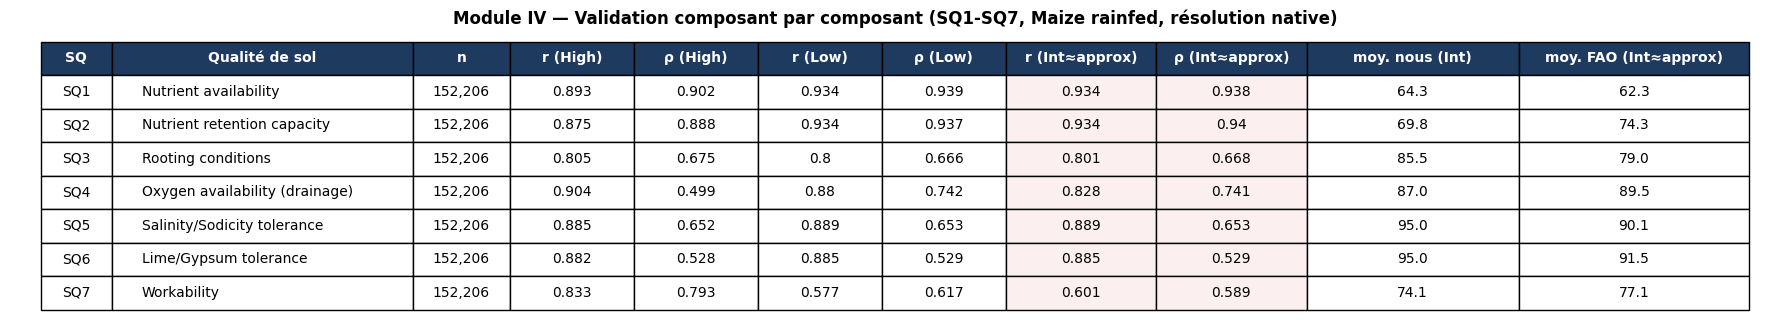

In [11]:
fig, ax = plt.subplots(figsize=(18, 3.3))
ax.axis('off')
col_labels = ['SQ', 'Qualité de sol', 'n', 'r (High)', 'ρ (High)', 'r (Low)', 'ρ (Low)',
              'r (Int≈approx)', 'ρ (Int≈approx)', 'moy. nous (Int)', 'moy. FAO (Int≈approx)']
col_widths = [0.04, 0.17, 0.055, 0.07, 0.07, 0.07, 0.07, 0.085, 0.085, 0.12, 0.13]
cell_text = [[r['SQ'], r['name'], f"{r['n_high']:,}", r['pearson_high'], r['spearman_high'],
              r['pearson_low'], r['spearman_low'], r['pearson_int'], r['spearman_int'],
              r['mean_ours_int'], r['mean_fao_int']]
             for r in sq_stats_rows]
table = ax.table(cellText=cell_text, colLabels=col_labels, colWidths=col_widths, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.9)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor('#1F3A5F')
        cell.set_text_props(color='white', fontweight='bold')
    if c == 1 and r > 0:
        cell.set_text_props(ha='left')
    if c in (7, 8) and r > 0:  # colonnes Intermediate - rappel que c'est une approximation
        cell.set_facecolor('#FBEFEF')
plt.title('Module IV — Validation composant par composant (SQ1-SQ7, Maize rainfed, résolution native)',
          fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(FIG_DIR / 'validation_stats_table_by_component.png', dpi=200, bbox_inches='tight')
plt.show()


## 8. Comparaison a 3 panneaux avec l'ancien module 1_SVM/2_soil_suitability (2026-10-14)

`1_SVM/2_soil_suitability/2.a)_Build_SoilSuitability_HWSD.ipynb` est un module de sol plus ancien
et plus simple (regle binaire construite directement sur HWSD2, sans la methodologie GAEZ SQ1-7,
sans distinction high/low input), encore utilise par \`6.a)_Apply_SoilConstraint_Future.ipynb\`
(scenarios AMOC) alors que tous les notebooks \`5.x)\` utilisent desormais ce module-ci (\`2_GAEZ\`,
corrige -- voir [[soil-suitability-module-iv-fixes]]). Verification visuelle demandee par
l'utilisatrice : les 3 panneaux ci-dessous montrent, cote a cote, l'ancien module (1deg, indice
0-1), notre calcul GAEZ (0.25deg, SSR 0-100) et le produit GAEZ v5 officiel (0.25deg, SSR 0-100),
pour Maize rainfed High input -- memes donnees que la section 5 ci-dessus, zoom Europe.

OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability\soil_suitability_outputs\soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf_wideextent.nc


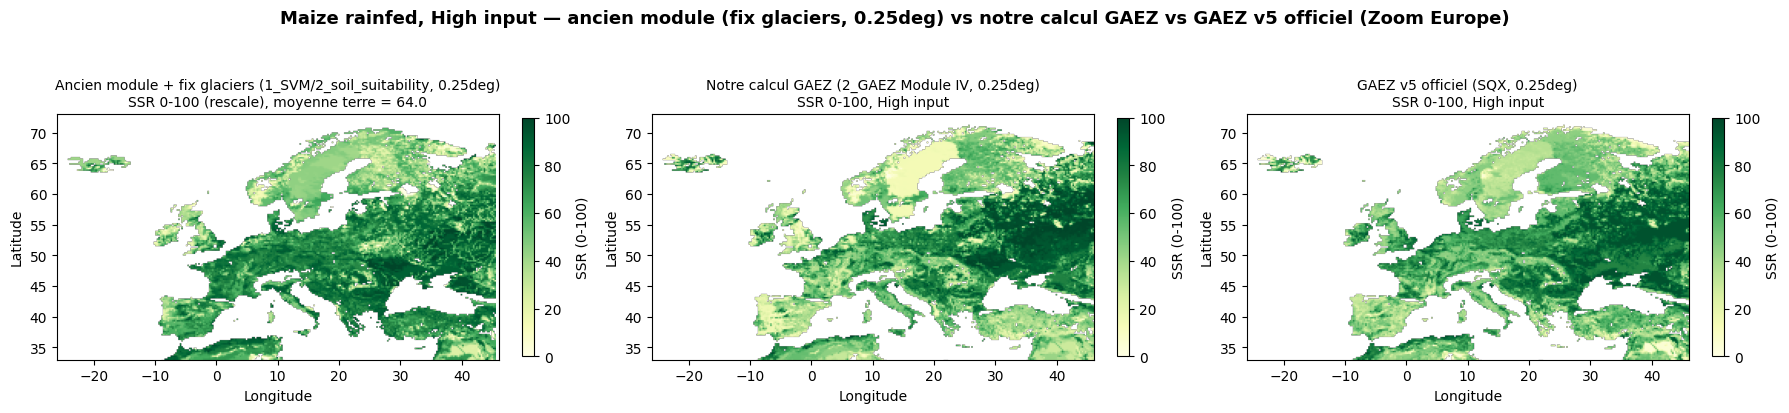

Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability\soil_validation_outputs\compare_old_module_glacierfix_vs_ours_vs_gaez_maize_rf_high_europe.png


In [12]:
OLD_SOIL_NC = BASE / "1_SVM" / "2_soil_suitability" / "soil_suitability_outputs" / "soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf_wideextent.nc"
print(f'{"OK" if OLD_SOIL_NC.exists() else "MISSING"}: {OLD_SOIL_NC}')
if OLD_SOIL_NC.exists():   # old module 2.a, not run in the global pipeline: comparison skipped without it
    ds_old = xr.open_dataset(OLD_SOIL_NC)
    old_idx = ds_old['soil_suit_idx_Maize_rf_glacierfix'] * 100.0  # 0-1 -> 0-100, meme echelle que les 2 autres panneaux
    old_lats, old_lons = old_idx.lat.values, old_idx.lon.values
    ds_old.close()

    OLD_VALIDATION_DIR = BASE / "1_SVM" / "2_soil_suitability" / "soil_validation_outputs"
    OLD_VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

    lon_min, lon_max, lat_min, lat_max = EUROPE_EXTENT
    aspect = (lon_max - lon_min) / (lat_max - lat_min)
    total_w = 18.0
    map_w = (total_w / 3) * 0.78
    map_h = map_w / aspect
    fig, axes = plt.subplots(1, 3, figsize=(total_w, map_h + 1.8), subplot_kw={'aspect': 'equal'})

    old_ext = [old_lons[0] - 0.125, old_lons[-1] + 0.125, old_lats[0] - 0.125, old_lats[-1] + 0.125]
    mask_pf_old = mask_pf.sel(lat=old_idx.lat, lon=old_idx.lon, method='nearest')  # meme grille 0.25deg, juste recadree Europe
    old_idx_masked = old_idx.where(~mask_pf_old.values)
    im0 = axes[0].imshow(old_idx_masked.values, origin='lower', extent=old_ext, cmap='YlGn', vmin=0, vmax=100)
    axes[0].set_title(f'Ancien module + fix glaciers (1_SVM/2_soil_suitability, 0.25deg)\nSSR 0-100 (rescale), moyenne terre = {float(old_idx_masked.mean(skipna=True)):.1f}', fontsize=10)
    plt.colorbar(im0, ax=axes[0], fraction=0.025, label='SSR (0-100)')

    im1 = axes[1].imshow(ours_high.where(~mask_pf), origin='upper', extent=[-180, 180, -90, 90], cmap='YlGn', vmin=0, vmax=100)
    axes[1].set_title('Notre calcul GAEZ (2_GAEZ Module IV, 0.25deg)\nSSR 0-100, High input', fontsize=10)
    plt.colorbar(im1, ax=axes[1], fraction=0.025, label='SSR (0-100)')

    im2 = axes[2].imshow(fao_him_da.where(~mask_pf), origin='upper', extent=[-180, 180, -90, 90], cmap='YlGn', vmin=0, vmax=100)
    axes[2].set_title('GAEZ v5 officiel (SQX, 0.25deg)\nSSR 0-100, High input', fontsize=10)
    plt.colorbar(im2, ax=axes[2], fraction=0.025, label='SSR (0-100)')

    for ax in axes:
        ax.set_xlim(lon_min, lon_max); ax.set_ylim(lat_min, lat_max)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')

    fig.suptitle('Maize rainfed, High input — ancien module (fix glaciers, 0.25deg) vs notre calcul GAEZ vs GAEZ v5 officiel (Zoom Europe)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OLD_VALIDATION_DIR / 'compare_old_module_glacierfix_vs_ours_vs_gaez_maize_rf_high_europe.png', dpi=180, bbox_inches='tight')
    plt.show()
    print(f"Saved: {OLD_VALIDATION_DIR / 'compare_old_module_glacierfix_vs_ours_vs_gaez_maize_rf_high_europe.png'}")
else:
    print('old soil module 2.a not available: section 8 skipped')


## 7. Conclusion

Le résultat le plus rigoureux (High vs HIM, niveaux réellement alignés) donne Spearman ρ ≈ 0.83 avec
l'architecture par composant — nette amélioration par rapport à la première tentative (mélange des
entrées, ρ ≈ 0.76 sur ce même test). Écarts résiduels attendus et documentés (tables v4, pondération
par couche approximée, régime non confirmé côté FAO, quantification 10 classes) — détail complet dans
`GAEZ_v5_Pipeline_Documentation.docx`.

En version binaire (seuil SSR ≥ 40), l'exactitude est de 84.7% (High vs HIM) et 84.0% (Intermediate) —
le désaccord se répartit à peu près aux deux tiers en « sous-estimation » (nous jugeons unsuitable
des pixels que GAEZ juge suitable) et un tiers en « sur-estimation », cohérent avec le fait que nos
notes moyennes sont globalement proches de GAEZ sans biais systématique dominant.

La validation composant par composant (section 6) permet d'identifier quelle(s) qualité(s) de sol
portent le plus l'écart résiduel, plutôt que de rester sur l'hypothèse globale "tables v4" sans plus
de précision.
